# Анализ лояльности пользователей билетного сервиса

**Автор:** Денис Куницын

**Дата:** 15 февраля 2026

## Цель и задачи

**Цель:** Исследователь профиль пользователя, который с наибольшей вероятностью возвращается на платформу и делает заказ повторно. 

**Задачи:**

1. Выгрузить данные из базы и познакомиться с ними.
2. Провести предобработку данных.
3. Сформировать профиль пользователя.
4. Провести исследовательский анализ данных: 
    - Изучить взаимосвязь данных с вероятностью повторой покупки.

## Данные

Для анализа выгрузили данные о заказах пользователей сервиса по продаже билетов. Данные состоят из одного датасета - `afisha_df`

### Описание датасета `afisha_df`

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

## Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Создание профиля пользователя. 
4. Исследовательский анализ данных.
5. Общий вывод и рекомендации.

---

## 1. Загрузка данных и знакомство с ними

Загрузим библиотеки и выгрузим датасет из базы данных. Используем pandas и библиотеки визуализации данных matplotlib и seaborn, а также phik для построения таблицы корреляции. Данные датасета сохраним в переменной `afisha_df`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik as phik_matrix
import os
import dotenv
from sqlalchemy import create_engine


In [2]:
dotenv.load_dotenv()

# Создаем конфиг с данными авторизации
db_config = {'user': os.getenv('DB_USER'), # имя пользователя
             'pwd': os.getenv('DB_PASSWORD'), # пароль
             'host': os.getenv('DB_HOST'),
             'port': os.getenv('DB_PORT'), # порт подключения
             'db': os.getenv('DB_NAME') # название базы данных
             }

# Формируем строку для подключения к базе
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

# Соединяемся с базой
engine = create_engine(connection_string)

In [3]:
# Пишем запрос для выгрузки данных и базы
query = '''
SELECT 
  p.user_id,
  p.device_type_canonical,
  p.order_id,
  p.created_dt_msk AS order_dt,
  p.created_ts_msk AS order_ts,
  p.currency_code,
  p.revenue,
  p.tickets_count,
  p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER(PARTITION BY p.user_id ORDER BY p.created_dt_msk) AS days_since_prev,
  p.event_id,
  e.event_name_code AS event_name,
  e.event_type_main,
  p.service_name,
  c.city_name,
  r.region_name
FROM afisha.purchases p
JOIN afisha.events e USING (event_id)
JOIN afisha.city c USING (city_id)
JOIN afisha.regions r USING (region_id)
WHERE device_type_canonical IN ('desktop', 'mobile') AND event_type_main != 'фильм'
ORDER BY user_id ASC
'''

In [4]:
# Выгружаем данные в переменную afisha_df
afisha_df = pd.read_sql_query(query, con=engine)

# Выводим первые строки датафрейма и проверяем результат
afisha_df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,city_name,region_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Глиногорск,Каменевский регион
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Глиногорск,Каменевский регион
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Глиногорск,Каменевский регион
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Озёрск,Североярская область
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Родниковецк,Озернинский край


In [5]:
# Информация о датафрейме
afisha_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Датафрейм `afisha_df` содержит 15 столбцов и 290611 строк.

После первичного анализа данных можно сделать следующие выводы:
- Представленные данные приведены к правильному типу данных. Однако, столбцы `tickets_count`, `days_since_prev`, `device_type_canonical`, `event_type_main` возможно оптимизировать.
- Пропуски содержатся только в столбце `days_since_prev`. Стоит проверить и другие столбцы на наличие значений-индикаторов пропусков.
- Для удобства дальнейшего анализа следует привести выручку к единой валюте.
- Значения в столбцах соотстветствуют своему описанию.

---

## 2. Предобработка данных 

### 2.1. Формирование столбца с выручкой в единой валюте

Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведем выручку к единой валюте - российскому рублю. 

Для этого используем датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год - `final_tickets_tenge_df.csv`.

Результаты преобразования сохраним в столбец `revenue_rub`.

In [6]:
# Загружаем датасет отношения
final_tickets_tenge_df = pd.read_csv(os.getenv('DB_CURRENCY'))

# Проверяем
final_tickets_tenge_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [7]:
# Преобразовываем тип даты из object в datetime
final_tickets_tenge_df['data'] = pd.to_datetime(final_tickets_tenge_df['data'])

# Формируем словарь для эффективного поиска
curs_dict = final_tickets_tenge_df.set_index('data')['curs'].to_dict()

def switch_currency(row):
    if row['currency_code'] == 'kzt':
        curs = curs_dict.get(row['order_dt'])
        # Если нужна дата отсутствует - пропуск
        if curs is not None:
            return row['revenue'] * (curs / 100)
    else:
        return row['revenue']

# Создаем новый столбец
afisha_df['revenue_rub'] = afisha_df.apply(switch_currency, axis=1)

# Проверяем результат
afisha_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Выручка успешно приведена к единой валюте. Решение не создало новых пропусков в столбце.

---

### 2.2. Поиск пропусков, оптимизация данных, фильтрация 

Первичный анализ данных показал наличие пропусков в столбце `days_since_prev`. Однако, стоит проверить остальные столбцы на наличие значений-индикаторов пропусков.

In [8]:
# Проверяем столбцы с категориальными значениями
for column in ['device_type_canonical', 'event_type_main', 'currency_code']:
        print(f"\nColumn: {column}")
        print("Уникальные значения:", afisha_df[column].unique())
        print("Пропущенные значения:", afisha_df[column].isna().sum())
        print("Количество значений:")
        print(afisha_df[column].value_counts(dropna=False), "\n")



Column: device_type_canonical
Уникальные значения: <StringArray>
['mobile', 'desktop']
Length: 2, dtype: str
Пропущенные значения: 0
Количество значений:
device_type_canonical
mobile     232490
desktop     58121
Name: count, dtype: int64 


Column: event_type_main
Уникальные значения: <StringArray>
['театр', 'выставки', 'другое', 'стендап', 'концерты', 'спорт', 'ёлки']
Length: 7, dtype: str
Пропущенные значения: 0
Количество значений:
event_type_main
концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: count, dtype: int64 


Column: currency_code
Уникальные значения: <StringArray>
['rub', 'kzt']
Length: 2, dtype: str
Пропущенные значения: 0
Количество значений:
currency_code
rub    285542
kzt      5069
Name: count, dtype: int64 



Значений-индикаторов пропусков не обнаружилось. Можно переходить к оптимизации типов данных.

---

In [9]:
# Оптимизируем категориальные данные
afisha_df['device_type_canonical'] = afisha_df['device_type_canonical'].astype('category')
afisha_df['event_type_main'] = afisha_df['event_type_main'].astype('category')

# Оптимизируем числовые данные
afisha_df['tickets_count'] = pd.to_numeric(afisha_df['tickets_count'], downcast='integer')
afisha_df['days_since_prev'] = pd.to_numeric(afisha_df['days_since_prev'].astype('Int64'), downcast='integer')

# Проверяем результат
afisha_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  Int16         
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  str           


Данные оптимизированы успешно.

---

Изучим распределение в численных данных и наличие в них выбросов. Важные показатели в рамках поставленной задачи - `tickets_count`, `revenue_rub`.

In [10]:
# Основные статистические показатели
afisha_df['tickets_count'].describe()

count    290611.000000
mean          2.754311
std           1.170620
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64

Среднее значение не сильно отличается от медианного, что указывает на отсутствие выбросов или их незначительное количество. Стандартное отклонение не высокое, что указывает на небольшую вариативность данных. 

Изучим данные с помощью диаграммы размаха.

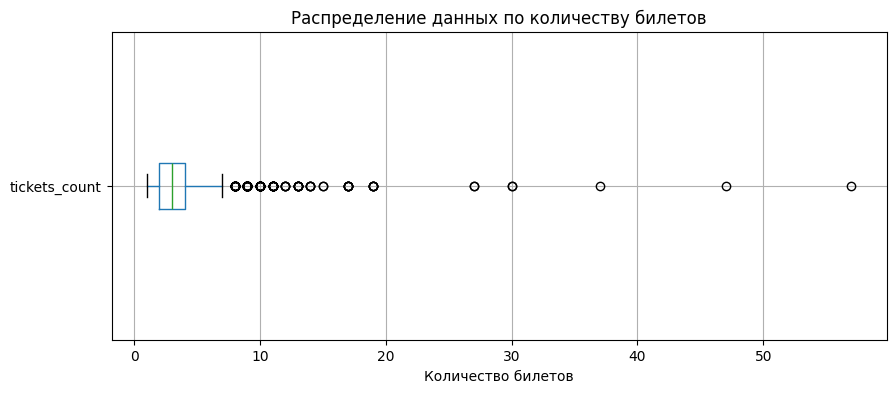

In [11]:
afisha_df.boxplot(column='tickets_count', vert=False, grid=True, figsize=(10, 4))

plt.title('Распределение данных по количеству билетов')
plt.xlabel('Количество билетов')
plt.show()

Гипотеза потвердилась - незначительное количество выбросов и низкая вариативность данных.

Это вполне объяснимо: в основном люди ходят в кино с романтическим партнером или группой друзей, то есть от 2 до 7 человек. Изредко, походы в кино организуются большими группами, например, школьными классами.

---

In [12]:
# Основные статистические показатели
afisha_df['revenue_rub'].describe()

count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

Заметим отрицательные значения в столбце. Возможно, это возвраты заказов. Избавимся от них заранее и перейдем к анализу графиков.

In [13]:
# Проверяем количество строк для удаления
afisha_df.shape[0] - afisha_df[afisha_df['revenue_rub'] >= 0].shape[0]

381

Количество строк невелико для удаления относительно датафрейма. Можем избавиться.

In [14]:
# Исключаем отрицательные значения из датафрейма
afisha_df = afisha_df[afisha_df['revenue_rub'] >= 0]

# Проверяем результат
afisha_df['revenue_rub'].describe()

count    290230.000000
mean        556.304587
std         875.838948
min          -0.000000
25%         114.610000
50%         352.080000
75%         802.250000
max       81174.540000
Name: revenue_rub, dtype: float64

Данные указывают на небольшое различие между медианным и средним значением. Высокий показатель стандартного отклонения, что указывает на большую вариативность данных.

Следует проверить данные с помощью инструментов визуализации.

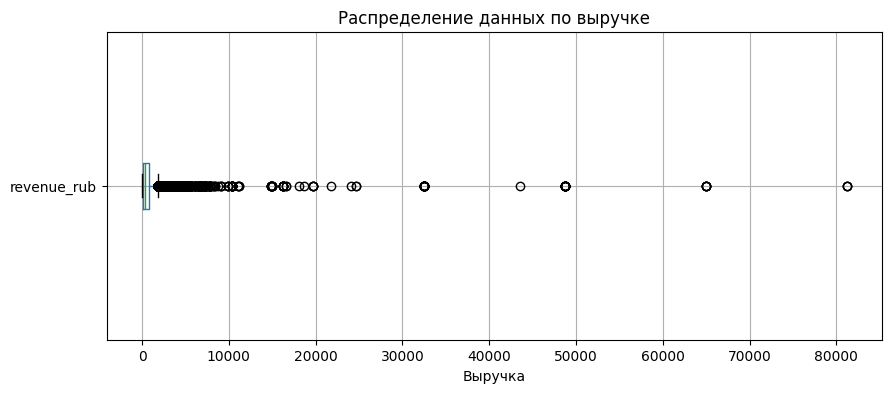

In [15]:
afisha_df.boxplot(
    column='revenue_rub', 
    vert=False, 
    grid=True, 
    figsize=(10, 4)
)

plt.title('Распределение данных по выручке')
plt.xlabel('Выручка')

plt.show()

График "ящика с усами" показал большие выбросы, которые затрудняют чтение графика. Исключим из данных 99-й перцентиль.

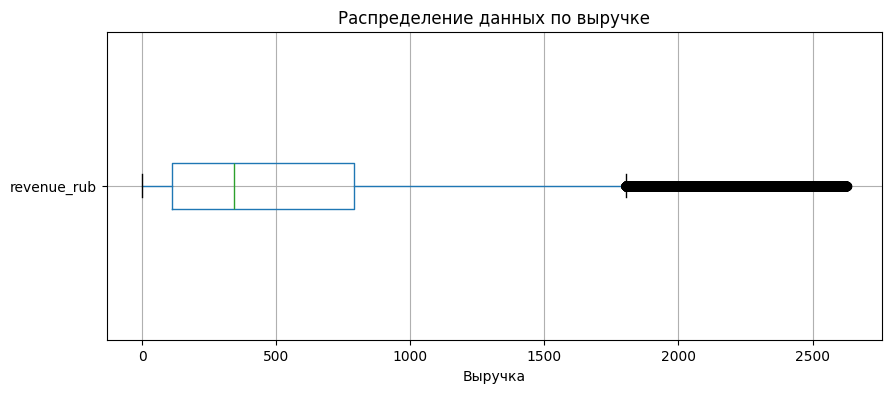

In [16]:
afisha_df[afisha_df['revenue_rub'] < afisha_df['revenue_rub'].quantile(0.99)].boxplot(
    column='revenue_rub', 
    vert=False, 
    grid=True, 
    figsize=(10, 4)
)

plt.title('Распределение данных по выручке')
plt.xlabel('Выручка')
plt.show()

После фильтрации график стал намного нагляднее. Рассмотрим также гистограмму данных.

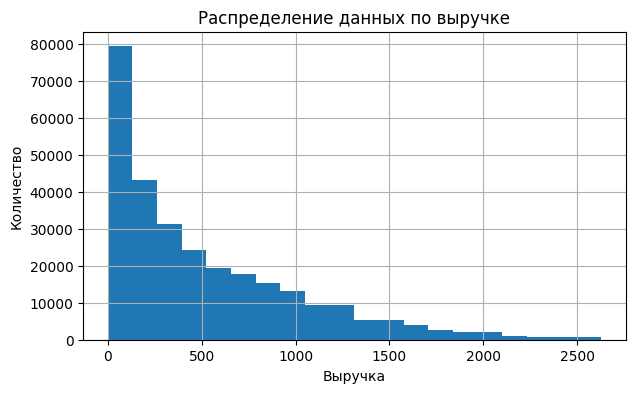

In [17]:
afisha_df[afisha_df['revenue_rub'] < afisha_df['revenue_rub'].quantile(0.99)].hist(
    column='revenue_rub', 
    bins=20, 
    grid=True, 
    figsize=(7, 4)
)
plt.title('Распределение данных по выручке')
plt.xlabel('Выручка')
plt.ylabel('Количество')

plt.show()

Данные показатели левоассиметричное распределение с небольшим хвостом.

Чтобы выбросы не повлияли на дальнейший анализ данных мы отставим датафрейм отфильтрованным по 99-му перцентелю. Отфильтрованный датафрейм сохраним в переменной `filtered_afisha_df`.

In [18]:
# Сохраняем отфильтрованный датафрейм
filtered_afisha_df = afisha_df[afisha_df['revenue_rub'] < afisha_df['revenue_rub'].quantile(0.99)]

In [19]:
# Проверяем количество строк после удаления в относительных значениях
(afisha_df.shape[0] - filtered_afisha_df.shape[0]) / afisha_df.shape[0] * 100

1.0360748371980844

Удаленное количество строк - около процента. Такое количество удалений не исказит данные, поэтому является приемлемым для нас.

---

Теперь проанализируем данные на наличие дубликатов.

In [20]:
# Выводим количество явных дубликатов
filtered_afisha_df.duplicated().sum().item()

0

Также исследуем отдельные столбцы на наличие неявных дубликатов

In [21]:
# Дубликаты по order_id
filtered_afisha_df['order_id'].duplicated().sum().item()

0

In [22]:
# Дубликаты при задублированнии при ошибке
filtered_afisha_df[[
    'user_id', 
    'device_type_canonical', 
    'order_dt',
    'order_ts',
    'currency_code',
    'tickets_count',
    'event_id',
    'event_name',
    'service_name',
    'city_name',
    'region_name',
    'revenue_rub'
]].duplicated().sum().item()

40

Обнаружились дубликаты в данных. Изучим их подробнее, чтобы убедиться: добавим параметр `keep=False`, чтобы посмотреть и на оригиналы, и на дубликаты. 

In [23]:
filtered_afisha_df[filtered_afisha_df.duplicated(subset=[
    'user_id', 
    'device_type_canonical', 
    'order_dt', 
    'order_ts',
    'currency_code',
    'tickets_count',
    'event_id',
    'event_name',
    'service_name',
    'city_name',
    'region_name',
    'revenue_rub'
], keep=False)].sort_values(by='user_id').head(10)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,city_name,region_name,revenue_rub
11758,06eb7897f65b433,mobile,1123867,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,Билеты в руки,Глиноград,Светополянский округ,69.82
11761,06eb7897f65b433,mobile,1123983,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,Билеты в руки,Глиноград,Светополянский округ,69.82
26876,0dc525d7bacbb0d,desktop,1930705,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,Лови билет!,Глиногорск,Каменевский регион,1556.05
26877,0dc525d7bacbb0d,desktop,1930763,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,Лови билет!,Глиногорск,Каменевский регион,1556.05
53681,206ea45ec11d478,mobile,1935113,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,Билеты в руки,Глиногорск,Каменевский регион,601.69
53682,206ea45ec11d478,mobile,1935171,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,Билеты в руки,Глиногорск,Каменевский регион,601.69
57173,2564e3703075008,mobile,160893,2024-10-30,2024-10-30 10:04:15,rub,11.23,2,0,589005,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,другое,Лови билет!,Горяново,Яблоневская область,11.23
57178,2564e3703075008,mobile,160922,2024-10-30,2024-10-30 10:04:15,rub,11.23,2,0,589005,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,другое,Лови билет!,Горяново,Яблоневская область,11.23
68163,2ecf0a4e24cae13,mobile,3326185,2024-10-17,2024-10-17 15:25:33,rub,40.33,2,0,481392,994dca15-357e-4193-9717-fd6e073f1354,театр,Билеты без проблем,Горнодолинск,Тепляковская область,40.33
68162,2ecf0a4e24cae13,mobile,3326272,2024-10-17,2024-10-17 15:25:33,rub,40.33,2,7,481392,994dca15-357e-4193-9717-fd6e073f1354,театр,Билеты без проблем,Горнодолинск,Тепляковская область,40.33


Все столбцы совпадают за исключением `order_id`: заказ пользователя мог задублироваться в системе, создасться с разными идентификаторами и временем заказа.

`40` дубликатов - крайне маленький процент данных в нашем датафрейме. Поэтому можем избавиться от дубликатов.

In [24]:
# Удаляем дубликаты из датафрейма
filtered_afisha_df.drop_duplicates(subset=[
    'user_id', 
    'device_type_canonical', 
    'order_dt',
    'order_ts',
    'currency_code',
    'tickets_count',
    'event_id',
    'event_name',
    'service_name',
    'city_name',
    'region_name',
    'revenue_rub'
], keep='first', inplace=True)

Дубликаты успешно удалены. Можем переходить к следующему этапу предобработки. 

---

Посмотрим, сколько строк было удалено в результате предобработки данных в абсолютных и относительных значениях. 

In [25]:
# Проверяем количество удаленных строк в абсолютных значениях
afisha_df.shape[0] - filtered_afisha_df.shape[0]

3047

In [26]:
# В относительных значениях
(afisha_df.shape[0] - filtered_afisha_df.shape[0]) / afisha_df.shape[0] * 100

1.0498570099576199

Всего удалено около 1% строк, что является приемлемым количеством для удаления.

---

**По итогам предобработки данных:**

- Были оптимизированы данные столбцов `days_since_prev`, `tickets_count`, `device_type_canonical`, `event_type_main`.
- Создан новый столбец `revenue_rub`, выражающий выручку каждого заказа в рублях.
- Удалено около 1% строк - дубликаты, отрицательная выручка (возвраты), выручка заказов, входивших в 99-й перцентиль.

---

## 3. Создание профиля пользователя

### 3.1. Простроение профиля

In [28]:
# Отсортируем данные по времени совершения заказа для удобства
filtered_afisha_df = filtered_afisha_df.sort_values(by='order_dt')

# Посчитаем статистику по пользователю
users_stats_df = filtered_afisha_df.groupby(by='user_id', as_index=False).agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    order_count=('order_id', 'count'),
    avg_revenue=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_since_prev=('days_since_prev', 'mean')
)

# Найдем первые заказы пользователей 
first_orders_df = filtered_afisha_df.groupby(by='user_id', as_index=False).first()[
    ['user_id', 
     'device_type_canonical', 
     'region_name', ''
     'service_name', 
     'event_type_main']
]
# После группировки останутся первые строки для каждого пользователя, в них - первые заказы

# Сформируем итоговый профиль пользователя
users_profiles_df = users_stats_df.merge(first_orders_df, how='left', on='user_id')

# Проверяем результат
users_profiles_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21832 entries, 0 to 21831
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   user_id                21832 non-null  str           
 1   first_order_dt         21832 non-null  datetime64[us]
 2   last_order_dt          21832 non-null  datetime64[us]
 3   order_count            21832 non-null  int64         
 4   avg_revenue            21832 non-null  float64       
 5   avg_tickets_count      21832 non-null  float64       
 6   avg_days_since_prev    13508 non-null  Float64       
 7   device_type_canonical  21832 non-null  category      
 8   region_name            21832 non-null  str           
 9   service_name           21832 non-null  str           
 10  event_type_main        21832 non-null  category      
dtypes: Float64(1), category(2), datetime64[us](2), float64(2), int64(1), str(3)
memory usage: 1.6 MB


Строк стало значительно меньше в сравнении с исходным датафреймом. Это может быть вполне объяснимо: уникальных пользователей было именно отображенное количество. На всякий случай проверим, сколько уникальных пользователей содержал исходный датафрейм.

In [29]:
len(filtered_afisha_df['user_id'].unique())

21832

Гипотеза подтвердилась. В датафрейме с профилями пользователей ровно то количество, которое должно быть.

Создадим 2 бинарных признака для удобства дальнейшего анализа - `is_two`, `is_five`. Признаки отображают, какое количество заказов совершил пользователь: два и более, пять и более соответственно. 

In [30]:
# Функция для проверки на 2 и более
def is_two(row):
    if row['order_count'] >= 2:
        return True
    return False

# Функция для проверки на 5 и более
def is_five(row):
    if row['order_count'] >= 5:
        return True
    return False    

# Создание новых столбцов
users_profiles_df['is_two'] = users_profiles_df.apply(is_two, axis=1)
users_profiles_df['is_five'] = users_profiles_df.apply(is_five, axis=1)

# Проверка результата
users_profiles_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21832 entries, 0 to 21831
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   user_id                21832 non-null  str           
 1   first_order_dt         21832 non-null  datetime64[us]
 2   last_order_dt          21832 non-null  datetime64[us]
 3   order_count            21832 non-null  int64         
 4   avg_revenue            21832 non-null  float64       
 5   avg_tickets_count      21832 non-null  float64       
 6   avg_days_since_prev    13508 non-null  Float64       
 7   device_type_canonical  21832 non-null  category      
 8   region_name            21832 non-null  str           
 9   service_name           21832 non-null  str           
 10  event_type_main        21832 non-null  category      
 11  is_two                 21832 non-null  bool          
 12  is_five                21832 non-null  bool          
dtypes: Float64(1

Поставленные задачи успешно выполнены, можно переходить к анализу профилей.

---

### 3.2. Анализ профиля

Для начала изучим статистические показатели:
- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между заказами;
- на наличие аномальных значений;

Затем изучим данные профилей пользователей после фильтрации, если она понадобится:
- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказов;
- долю пользователей, совершивших 5 и более заказов.

**Статистические показатели:**

По общему количеству заказов:

In [31]:
# Статистические показатели по общему количеству заказов
users_profiles_df['order_count'].describe()

count    21832.000000
mean        13.154223
std        121.514158
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10162.000000
Name: order_count, dtype: float64

Среднее значение сильно различается с медианным - в данных присутствуют выбросы. Высокое стандартное отклонение указывает на высокую вариативность, что отчасти может подтверждать гипотезу. Разница между минимальным и максимальным значениями также подтверждает гипотезу.

Отобразим данные на диаграмме размаха.

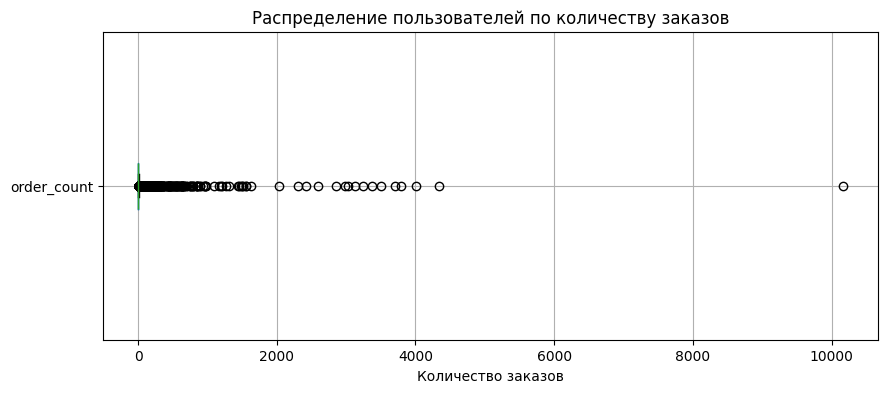

In [32]:
users_profiles_df.boxplot(column='order_count', vert=False, grid=True, figsize=(10, 4))

plt.title('Распределение пользователей по количеству заказов')
plt.xlabel('Количество заказов')

plt.show()

График отобразил большое количество выбросов. Выбросы негативно повлияют на анализ. Посмотрим какого количества данных мы лишимся при фильтрации по 95-му.

In [33]:
len(users_profiles_df[users_profiles_df['order_count'] < users_profiles_df['order_count'].quantile(0.95)]) / len(users_profiles_df)

0.9486991572004397

Если отфильтруем значения по 95-му перцентелю, сократим количество данных на 5 процентов. Это верхняя приемлемая граница, которая обозначена для неискажения результатов при анализе.

Отфильтруем данные по 95-му перцентелю и посмотрим на диаграмму размаха.

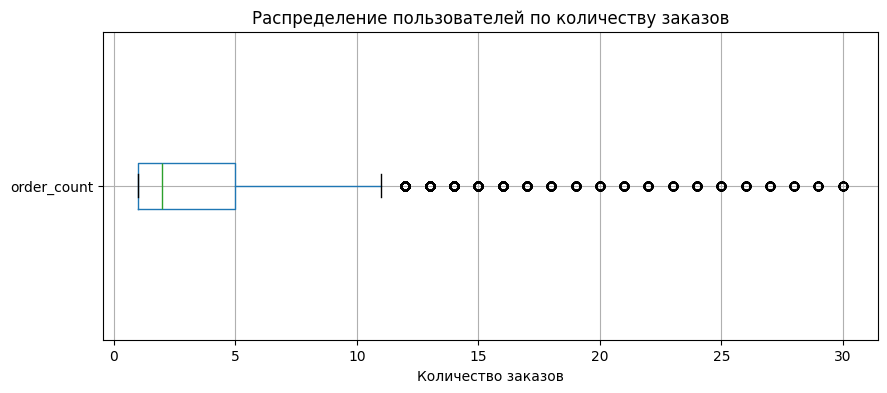

In [34]:
users_profiles_df[users_profiles_df['order_count'] < users_profiles_df['order_count'].quantile(0.95)].boxplot(column='order_count', vert=False, grid=True, figsize=(10, 4))

plt.title('Распределение пользователей по количеству заказов')
plt.xlabel('Количество заказов')

plt.show()

In [35]:
# Сохраняем отфильтрованный датафрейм
users_profiles_df = users_profiles_df[users_profiles_df['order_count'] < users_profiles_df['order_count'].quantile(0.95)]

Мы сократили выбросы и теперь данные выглядят более репрезентативными. 

---

По среднему числу билетов в заказе:

In [36]:
# Общие статистические значения 
users_profiles_df['avg_tickets_count'].describe()

count    20712.000000
mean         2.744462
std          0.935373
min          1.000000
25%          2.000000
50%          2.750000
75%          3.166667
max         11.000000
Name: avg_tickets_count, dtype: float64

Среднее значение практически идентично медиане, низкий показатель стандратного отклонения указывает на небольшую вариативность данных. Разница между минимальным и максимальным значениями не слишком велика. Можно сделать заключение о том, что выбросов нет или их минимальное количество.

---

По среднему количеству дней между покупками:

In [37]:
# Общие статистические значения
users_profiles_df['avg_days_since_prev'].describe()

count      12388.0
mean     17.094218
std      22.907918
min            0.0
25%            1.0
50%            9.5
75%           22.2
max          148.0
Name: avg_days_since_prev, dtype: Float64

Среднее значение и медиана различаются - возможны выбросы. Высокое стандартное отклонение указывает на большую вариативность данных. 

Проанализируем данные с помощью диаграммы размаха.

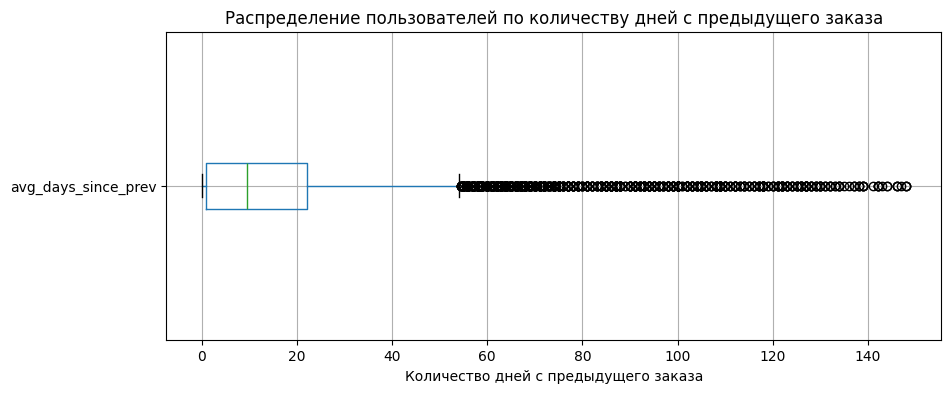

In [38]:
users_profiles_df.boxplot(column='avg_days_since_prev', vert=False, grid=True, figsize=(10, 4))

plt.title('Распределение пользователей по количеству дней с предыдущего заказа')
plt.xlabel('Количество дней с предыдущего заказа')

plt.show()

Диаграмма размаха показала наличие выбросов, однако, не такое большое, чтобы исказить результаты исследования.

Не будем изменять данные.

---

**Данные профилей пользователей:**

In [39]:
# Общее число пользователей в выборке
len(users_profiles_df['user_id'].unique())

20712

In [40]:
# Средняя выручка с одного заказа
users_profiles_df['avg_revenue'].mean().item()

546.4649475986139

In [41]:
# Доля пользователей, совершивших 2 и более заказов
users_profiles_df['is_two'].mean().item()

0.5963692545384318

In [42]:
# Доля пользователей, совершивших 5 и более заказов
users_profiles_df['is_five'].mean().item()

0.2514484356894554

---

### Промежуточный вывод

Был построен датафрейм с данными профиля для каждого пользователя:
- `user_id` - идентификатор пользователя;
- `first_order_dt` - дата первого заказа;
- `last_order_df` - дата последнего заказа;
- `order_count` - количество заказов;
- `avg_revenue` - средний чек;
- `avg_tickets_count` - среднее количество билетов;
- `avg_days_since_prev` - среднее количество дней между заказами;
- `device_type_canonical` - тип девайся, с которого был сделан первый заказ;
- `region_name` - регион первого заказа;
- `service_name` - билетный партнер, к которому обращались при первом заказе;
- `event_type_main` - тип мероприятия первого посещения.

Анализ данных профилей пользователей:
- Общее число пользователей - 20755
- Средняя выручка с одного заказа - 545.7 
- Доля пользователей, совершивших 2 и более заказов - 0.6
- Доля пользователей, совершивших 5 и более заказов - 0.25

---

## 4. Исследовательский анализ данных

Основная цель исследовательского анализа данных - исследовать признаки, влияющие на возврат пользователей, то есть на совершение повторного заказа.

### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

**4.1.1. Изучение распределения пользователей по признакам.**

Сегментируем пользователей по следующим признакам:
- по типу их первого мероприятия;
- по типу устройства, с которого совершена первая покупка;
- по региону проведения;
- по билетному оператору, продавшему билеты на первый заказ.

**По типу первого мероприятия:**

In [43]:
users_profiles_df.groupby(by='event_type_main')['user_id'].count().sort_values(ascending=False)

event_type_main
концерты    9172
другое      5171
театр       4051
стендап     1066
спорт        763
выставки     399
ёлки          90
Name: user_id, dtype: int64

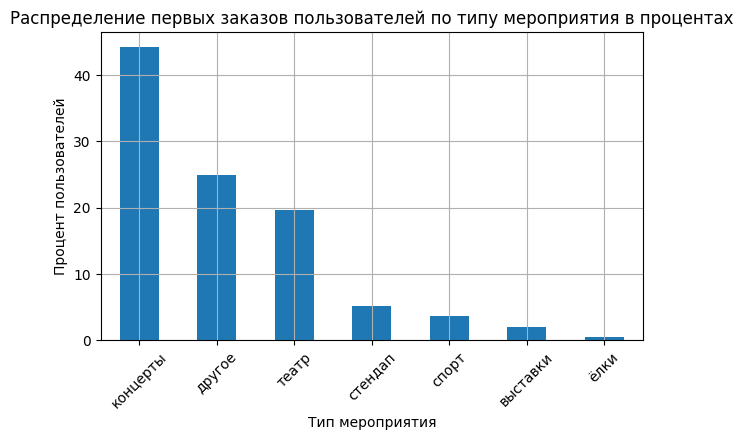

In [44]:
(users_profiles_df.groupby(by='event_type_main')['user_id'].count() / len(users_profiles_df) * 100).sort_values(ascending=False).plot(
    kind='bar',
    legend=False,
    rot=45,
    grid=True,
    figsize=(7, 4),
    xlabel='Тип мероприятия',
    ylabel='Процент пользователей',
    title='Распределение первых заказов пользователей по типу мероприятия в процентах'
)

plt.show()

Наибольшее количество пользователей начинает знакомство с сервисом через приобретение билетов на концерты.

---

**По типу устройства, с которого совершена первая покупка**

In [45]:
users_profiles_df.groupby(by='device_type_canonical')['user_id'].count().sort_values()

device_type_canonical
desktop     3544
mobile     17168
Name: user_id, dtype: int64

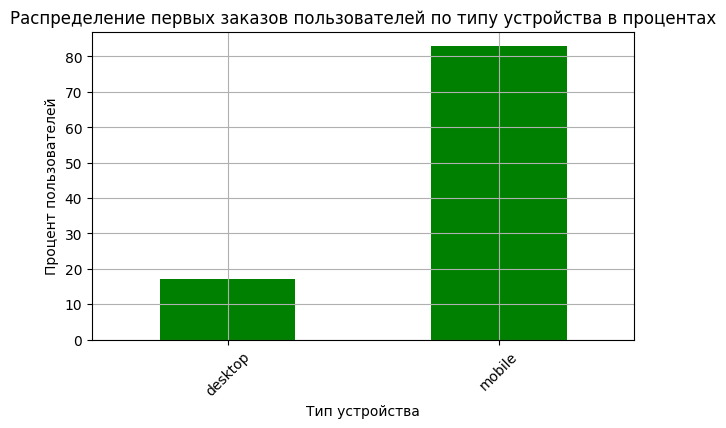

In [46]:
(users_profiles_df.groupby(by='device_type_canonical')['user_id'].count() / len(users_profiles_df) * 100).sort_values().plot(
    kind='bar',
    legend=False,
    rot=45,
    grid=True,
    color='green',
    figsize=(7, 4),
    xlabel='Тип устройства',
    ylabel='Процент пользователей',
    title='Распределение первых заказов пользователей по типу устройства в процентах'
)
plt.show()

Более 80% пользователей совершают свой первый заказ с мобильного устройства. Это неудивительно, ведь мобильное устройство всегда под рукой и есть практически у каждого человека.

---

**По региону проведения:**

In [47]:
users_profiles_df.groupby(by='region_name')['user_id'].count().sort_values(ascending=False)

region_name
Каменевский регион          6754
Североярская область        3602
Широковская область         1185
Озернинский край             664
Малиновоярский округ         516
                            ... 
Залесский край                 2
Верхозёрский край              1
Светолесский край              1
Сосноводолинская область       1
Яснопольский округ             1
Name: user_id, Length: 81, dtype: int64

Так как регионов много, мы оставим первую десятку, которая является наиболее репрезентативной.

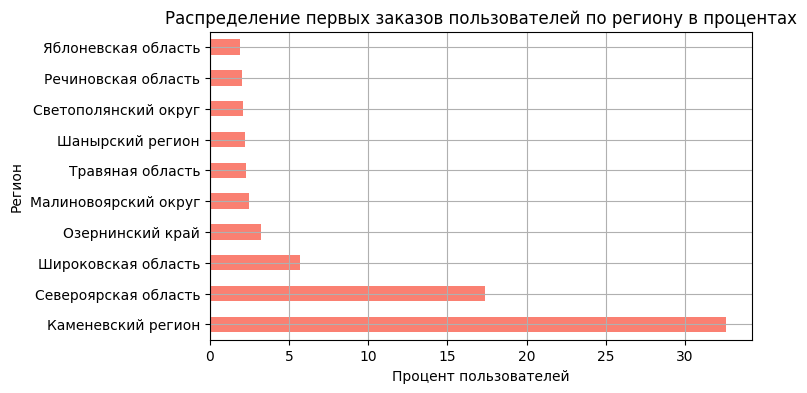

In [48]:
(users_profiles_df.groupby(by='region_name')['user_id'].count() / len(users_profiles_df) * 100).sort_values(ascending=False).head(10).plot(
    kind='barh',
    legend=False,
    rot=0,
    grid=True,
    color='salmon',
    figsize=(7, 4),
    xlabel='Процент пользователей',
    ylabel='Регион',
    title='Распределение первых заказов пользователей по региону в процентах'
)

plt.show()

Наибольшее количество пользователей совершает первый заказ в Каменевском регионе, Североярской и Широковской областях.

---

**По билетному оператору:**

In [49]:
users_profiles_df.groupby(by='service_name')['user_id'].count().sort_values(ascending=False)

service_name
Билеты без проблем        4943
Мой билет                 2841
Лови билет!               2705
Билеты в руки             2420
Облачко                   2110
Весь в билетах            1235
Лучшие билеты             1130
Прачечная                  550
Край билетов               432
Дом культуры               334
Яблоко                     308
Тебе билет!                295
Городской дом культуры     213
За билетом!                200
Мир касс                   199
Быстробилет                159
Show_ticket                157
Выступления.ру              94
Восьмёрка                   84
Быстрый кассир              55
Crazy ticket!               39
Росбилет                    38
Радио ticket                35
Телебилет                   28
Реестр                      27
Цвет и билет                21
Шоу начинается!             18
КарандашРУ                  14
Кино билет                   9
Вперёд!                      7
Билет по телефону            6
Тех билет                 

Для удобства чтения выведем первую 10-ку операторов.

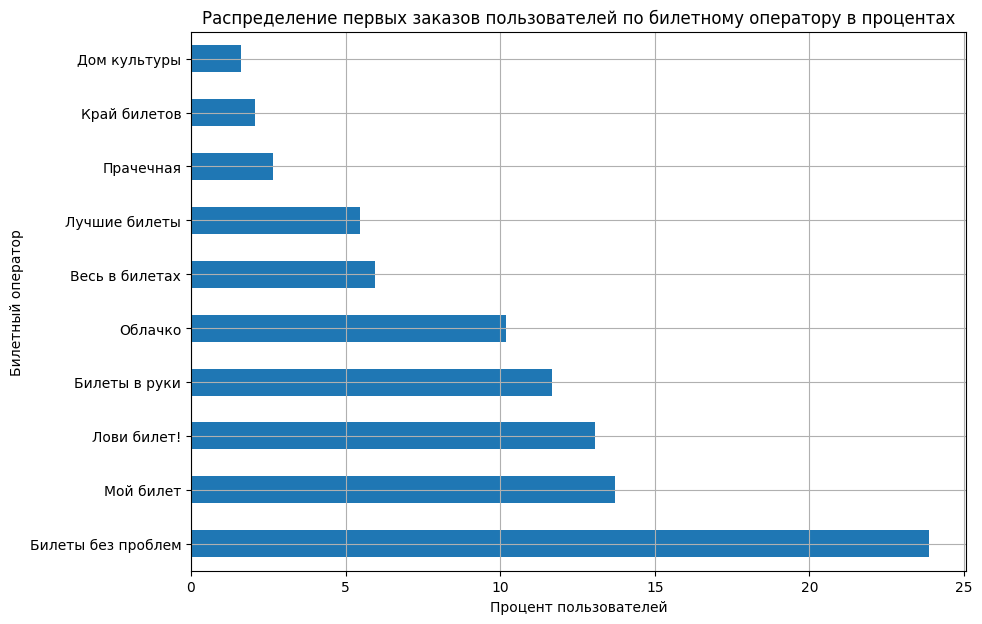

In [50]:
(users_profiles_df.groupby(by='service_name')['user_id'].count() / len(users_profiles_df) * 100).sort_values(ascending=False).head(10).plot(
    kind='barh',
    legend=False,
    rot=0,
    grid=True,
    figsize=(10, 7),
    xlabel='Процент пользователей',
    ylabel='Билетный оператор',
    title='Распределение первых заказов пользователей по билетному оператору в процентах'
)

plt.show()

В первую семерку по популярности среди первого заказа у пользователей вошли билетные операторы: `Билеты без проблем`, `Мой билет`, `Лови билет!`, `Билеты в руки`, `Облачко`, `Весь в билетах`, `Лучшие билеты`.

---

**4.1.2. Анализ возврата пользователей**

Для каждого сегмента вычислим долю пользователей, совершивших 2 и более заказов. 

**По типу первого мероприятия:**

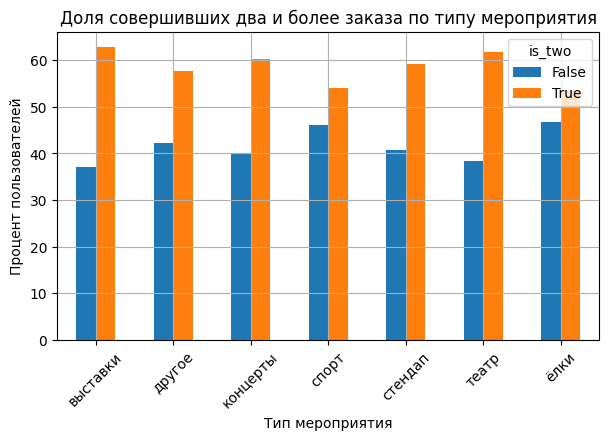

In [51]:
(users_profiles_df.groupby(by='event_type_main')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100).plot(
    kind='bar',
    legend=True,
    rot=45,
    grid=True,
    figsize=(7, 4),
    xlabel='Тип мероприятия',
    ylabel='Процент пользователей',
    title='Доля совершивших два и более заказа по типу мероприятия'
)

plt.show()

В каждом из сегментов типов мероприятия пользователи возвращаются в сервис примерно в 60% случаев. Сильно выделяющихся сегментов не обнаружено.

---

**По типу устройства, с которого совершена первая покупка:**

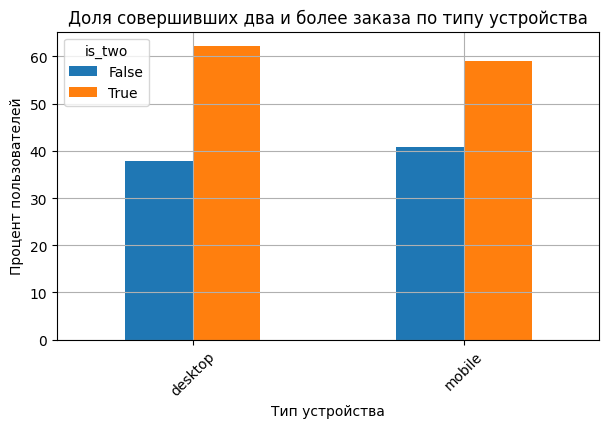

In [52]:
(users_profiles_df.groupby(by='device_type_canonical')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100).plot(
    kind='bar',
    legend=True,
    rot=45,
    grid=True,
    figsize=(7, 4),
    xlabel='Тип устройства',
    ylabel='Процент пользователей',
    title='Доля совершивших два и более заказа по типу устройства'
)

plt.show()

Также нет наиболее выраженых сегментов по доле вернувшихся пользователей.

---

**По региону проведения:**

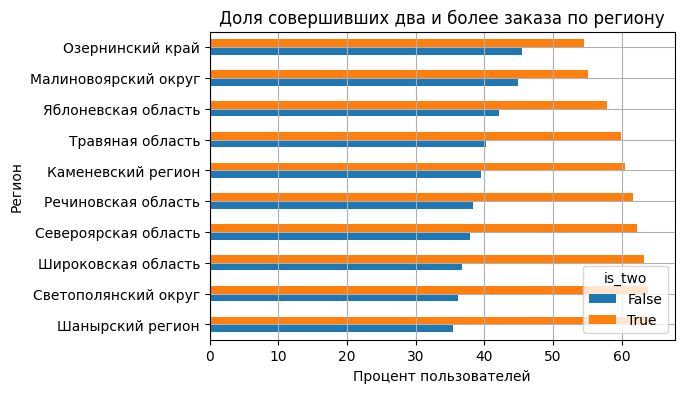

In [53]:
# Выделяем топ-10 регионов по количеству первых заказов
top10_regions = users_profiles_df.groupby(by='region_name')['user_id'].count().reset_index().sort_values(by='user_id', ascending=False)['region_name'].head(10)

# Фильтруем датафрейм по региону
filtered_by_region = users_profiles_df[users_profiles_df['region_name'].isin(top10_regions)]

# Подготавливаем данные к визуализации
plot_data = filtered_by_region.groupby('region_name')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100

# Сортируем данные
plot_data = plot_data.sort_values(by=True, ascending=False)

plot_data.plot(
    kind='barh',
    legend=True,
    rot=0,
    grid=True,
    figsize=(6, 4),
    xlabel='Процент пользователей',
    ylabel='Регион',
    title='Доля совершивших два и более заказа по региону'
)

plt.show()



Наибольший процент оставшихся в сервисе пользователей в Шанырском регионе. Однако, доля не сильно выше остальных регионов

---

**По билетному оператору:**

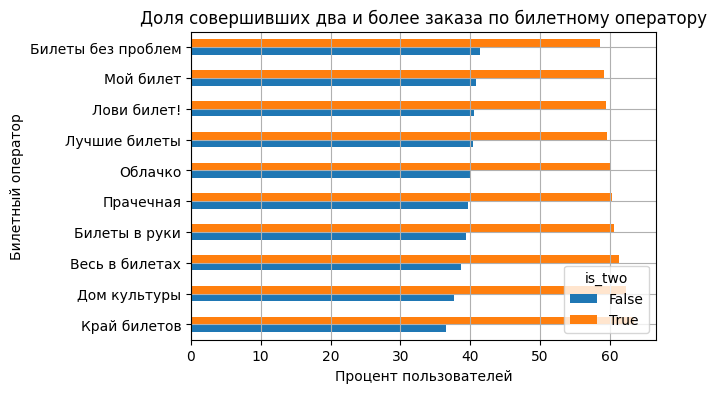

In [54]:
# Выделяем топ-10 билетных операторов по количеству первых заказов
top10_regions = users_profiles_df.groupby(by='service_name')['user_id'].count().reset_index().sort_values(by='user_id', ascending=False)['service_name'].head(10)

# Фильтруем датафрейм по региону
filtered_by_region = users_profiles_df[users_profiles_df['service_name'].isin(top10_regions)]

# Подготавливаем данные к визуализации
plot_data = filtered_by_region.groupby('service_name')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100

# Сортируем данные
plot_data = plot_data.sort_values(by=True, ascending=False)

plot_data.plot(
    kind='barh',
    legend=True,
    rot=0,
    grid=True,
    figsize=(6, 4),
    xlabel='Процент пользователей',
    ylabel='Билетный оператор',
    title='Доля совершивших два и более заказа по билетному оператору'
)

plt.show()



Доля оставшихся пользователей практически не меняется от оператора к оператору.

---

**4.1.3. Проверка продуктовых гипотез**

**Гипотеза 1:** Тип мероприятия влияет на вероятность возврата в сервис: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.

**Вывод:** Гипотеза не подтвердилась. Картина выглядит ровно противоположным образом: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ реже, чем пользователи, оформившие свой первый заказ на концерты. По наибольшей доли оставшихся пользователей можно отметить следующие типы: `театр`, `концерты`, `выставки`.

**Гипотеза 2:** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

**Вывод:** Гипотеза не подтвердилась. Три наиболее популярных регионов по проценту первого заказа: `Каменевский регион`, `Североярская область`, `Широковская область`. Среди регионов с наибольшей долей оставшихся пользователей: `Шанырский регион`, `Светополянский округ`, `Широковская область`. Причем `Каменевский регион` и `Североярская область` ближе к середине списка.

---

### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

**4.2.1. Нахождение связи между средней выручкой сервиса с заказа и повторными заказами**

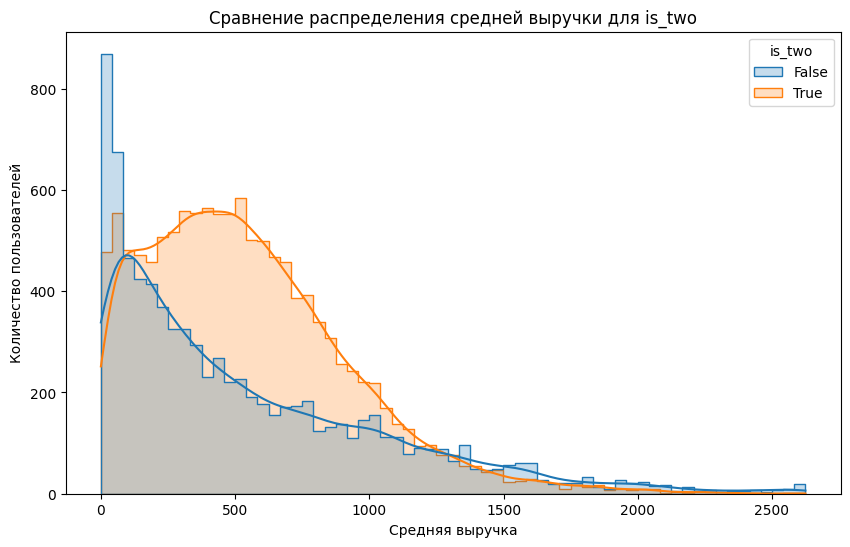

In [55]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=users_profiles_df, 
    x='avg_revenue', 
    hue='is_two',       
    kde=True,           
    element='step',     
    common_norm=False
)

plt.title('Сравнение распределения средней выручки для is_two')
plt.xlabel('Средняя выручка')
plt.ylabel('Количество пользователей')
plt.show()


Группа, совершившая 1 заказ (синий цвет), часто имеет более низкий средний чек. Основные значения группы лежат в диапазоне от 0 до 500 руб. 

Группа, совершившая 2 и более заказов (оранжевый цвет), чаще имеет более высокий средний чек. Основные значения лежат в диапазоне от 0 до 1200 руб.

---

**4.2.2. Сравнение распределения по средней выручке заказа в двух группах пользователей:**
- совершившие 2-4 заказа;
- совершившие 5 и более заказов.

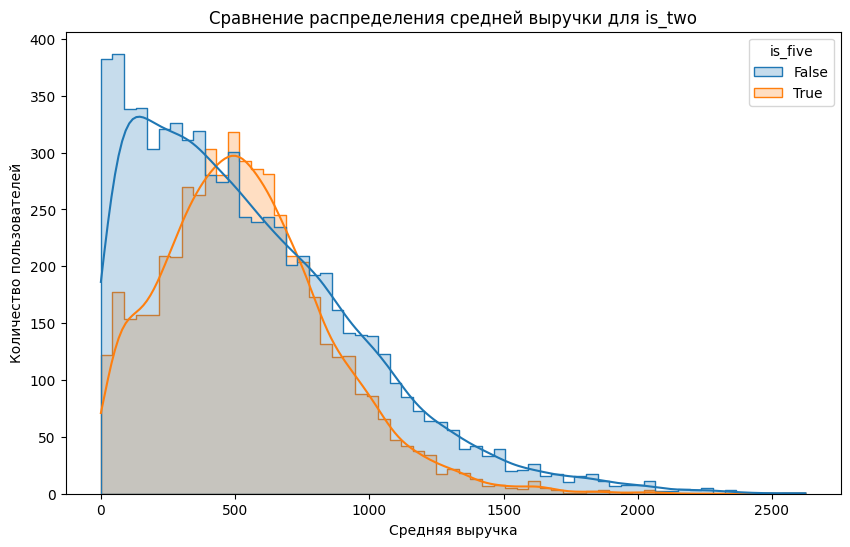

In [56]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=users_profiles_df[users_profiles_df['is_two']], # Оставляем только заказы 2 и более 
    x='avg_revenue', 
    hue='is_five', # Единичные заказы исключены  
    kde=True,           
    element='step',     
    common_norm=False
)

plt.title('Сравнение распределения средней выручки для is_two')
plt.xlabel('Средняя выручка')
plt.ylabel('Количество пользователей')
plt.show()


Группа, совершивших 2-4 заказа, распределена в сторону низкой средней выручки. Группа распределена в диапазоне от 0 до 500 руб. 

Группа, совершившая 5 и более заказов, распределена менее в сторону низкой средней вырочки и больше представлена в диапазоне от 0 до 1000 руб. 

---

**4.2.3. Анализ влияния среднего количества билетов в заказе на вероятность повторной покупки.**

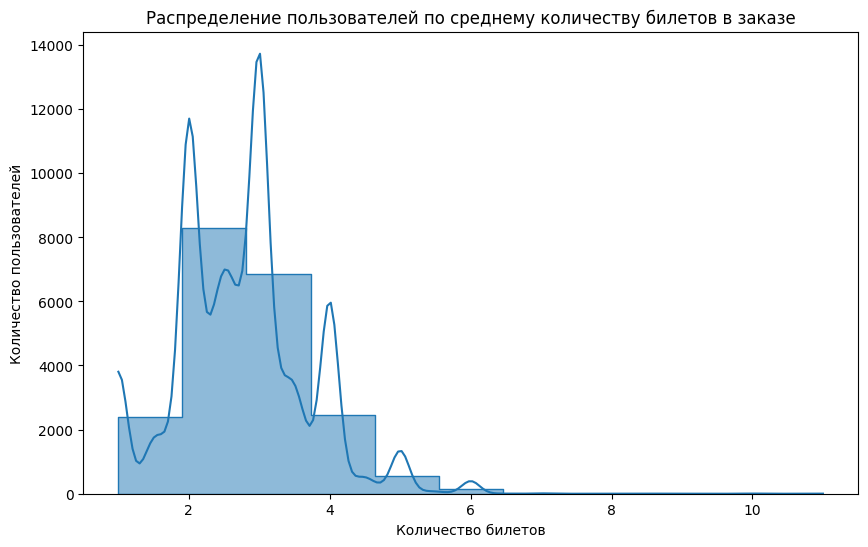

In [57]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=users_profiles_df,
    x='avg_tickets_count',
    bins=11,
    kde=True,
    element='step'
)

plt.title('Распределение пользователей по среднему количеству билетов в заказе')
plt.xlabel('Количество билетов')
plt.ylabel('Количество пользователей')

plt.show()

Основное количество билетов находится в диапазоне от 1 до 5 шт.

Больше всего в среднем 2 и 3 билета.

---

Разделим пользователей на сегменты:
- от 1 до 2 билетов;
- от 2 до 3 билетов;
- от 3 до 5 билетов;
- от 5 и более билетов.

In [58]:
# Создаем функцию сегментации по среднему количеству билетов
def tickets_segmentation(row):
    if row['avg_tickets_count'] >= 5:
        return 'от 5 и более билетов'
    elif row['avg_tickets_count'] >= 3:
        return 'от 3 до 5 билетов'
    elif row['avg_tickets_count'] >= 2:
        return 'от 2 до 3 билетов'
    elif row['avg_tickets_count'] >= 1:
        return 'от 1 до 2 билетов'
    else:
        return 'Ошибка сегментации'

In [59]:
# Создаем новый столбец с сегментом
users_profiles_df['tickets_segment'] = users_profiles_df.apply(tickets_segmentation, axis=1)

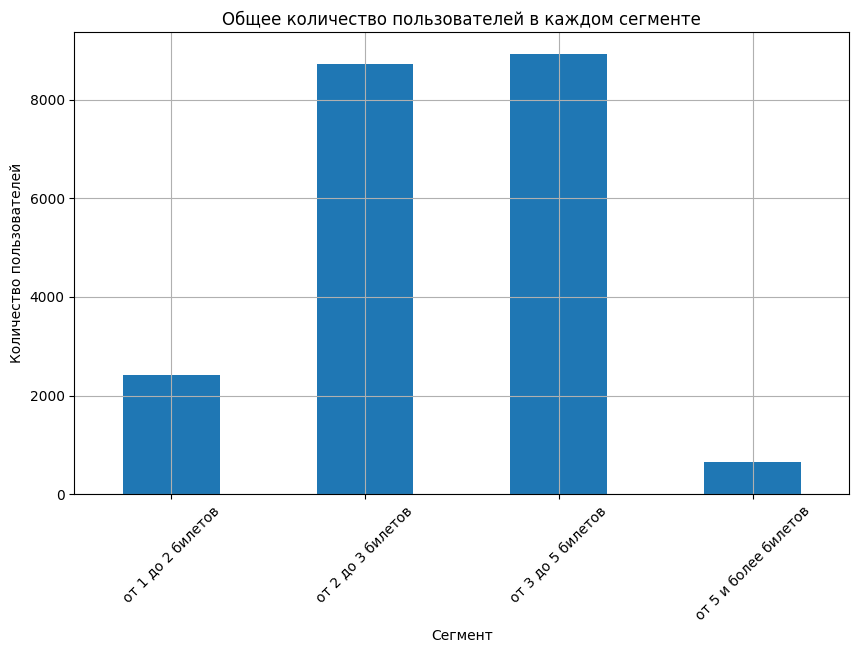

In [60]:
users_profiles_df.groupby(by='tickets_segment')['user_id'].count().plot(
    kind='bar',
    rot=45,
    grid=True,
    figsize=(10, 6),
    title='Общее количество пользователей в каждом сегменте',
    xlabel='Сегмент',
    ylabel='Количество пользователей'
)

plt.show()


Больше всего пользователей в двух сегментах: `от 2 до 3 билетов` и `от 3 до 5 билетов`.

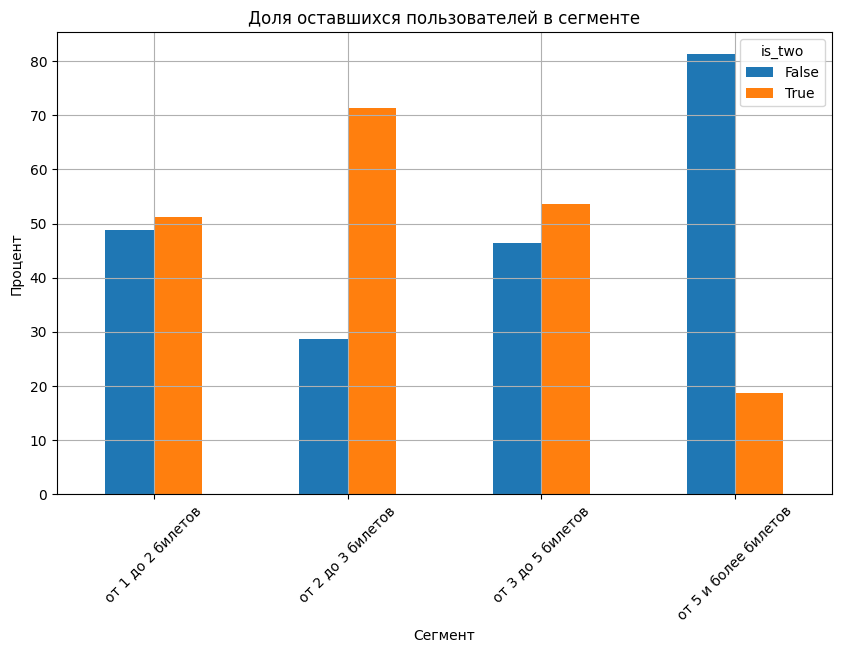

In [61]:
(users_profiles_df.groupby(by='tickets_segment')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100).plot(
    kind='bar',
    rot=45,
    grid=True,
    figsize=(10, 6),
    title='Доля оставшихся пользователей в сегменте',
    xlabel='Сегмент',
    ylabel='Процент'
)

plt.show()

Из прошлых данных известно, что среднее количество оставшихся пользователей для всех данных около 60%. Особенно выделяется сегмент `от 2 до 3 билетов`, т.к. доля оставшихся пользоваталей в этом сегменте свыше 70%.

Также выделяется сегмент `от 5 и более билетов` с аномальной низкой долей оставшихся пользователей - свыше 80%. 

---

### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки.

**4.3.1. Анализ влияния дня недели первой покупки на поведение пользователя.**

In [62]:
# Добавляем столбец с днем недели первой покупки
users_profiles_df['first_order_weekday'] = users_profiles_df['first_order_dt'].dt.day_of_week

# Считаем количество пользователей, совершивших первую покупку в определенный день недели
# Где 0 - понедельник, 6 - воскресенье
users_profiles_df.groupby(by='first_order_weekday')['user_id'].count()

first_order_weekday
0    2809
1    3009
2    2958
3    3023
4    3158
5    3118
6    2637
Name: user_id, dtype: int64

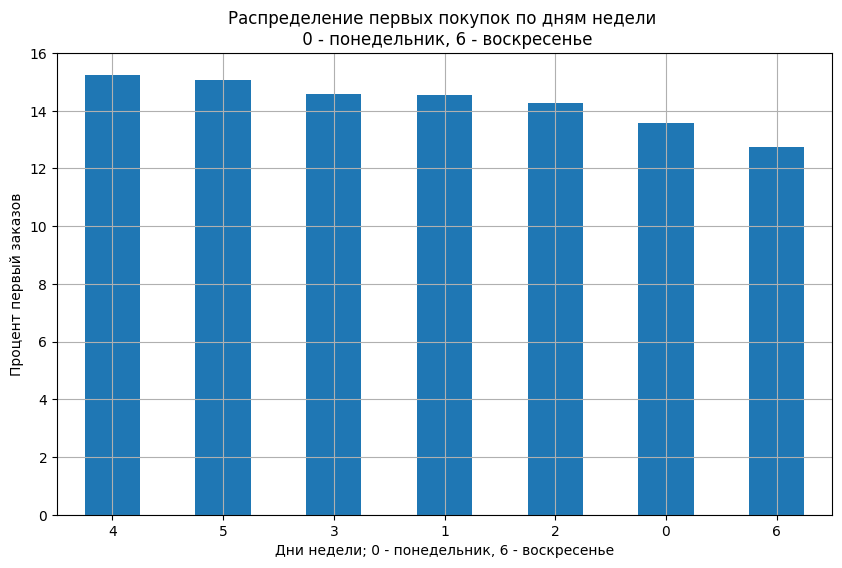

In [63]:
# Визуализируем долю пользователей для каждого дня недели
plt.figure(figsize=(10, 6))

(users_profiles_df.groupby(by='first_order_weekday')['user_id'].count() / len(users_profiles_df) * 100).sort_values(ascending=False).plot(
    kind='bar',
    rot=0,
    grid=True,
    title='Распределение первых покупок по дням недели \n 0 - понедельник, 6 - воскресенье',
    xlabel='Дни недели; 0 - понедельник, 6 - воскресенье',
    ylabel='Процент первый заказов'
)

plt.show()

Распределение по дням недели от дня к дню практически идентично. Наивысшая доля первых покупок приходится на субботу, а наименьшая доля на воскресенье.

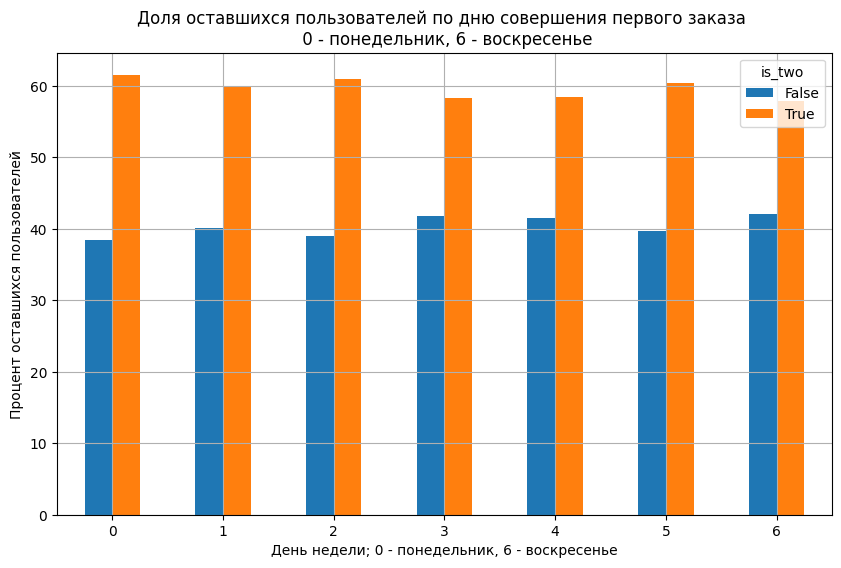

In [64]:
(users_profiles_df.groupby(by='first_order_weekday')['is_two'].value_counts(normalize=True).unstack(fill_value=0) * 100).plot(
    kind='bar',
    rot=0,
    grid=True,
    figsize=(10, 6),
    title='Доля оставшихся пользователей по дню совершения первого заказа \n 0 - понедельник, 6 - воскресенье',
    xlabel='День недели; 0 - понедельник, 6 - воскресенье',
    ylabel='Процент оставшихся пользователей'
)

plt.show()

Совершение первой покупки в определенный день недели также не влияет на долю оставшихся пользователей.

---

**4.3.2. Влияние среднего интервала между заказами на удержание клиентов.**



In [65]:
# Подготавливаем датафрейм к визуализации
users_profiles_df['avg_days_since_prev'] = users_profiles_df['avg_days_since_prev'].astype('float64')

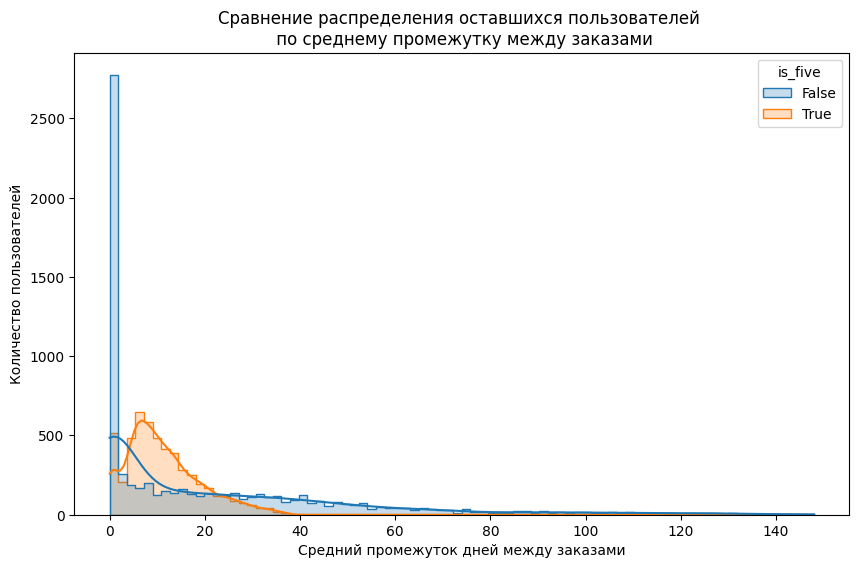

In [66]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=users_profiles_df[users_profiles_df['is_two']], # Оставляем только заказы 2 и более
    x='avg_days_since_prev',
    hue='is_five', # Единичные заказы исключены
    kde=True,
    element='step',
    common_norm=False
)

plt.title('Сравнение распределения оставшихся пользователей \n по среднему промежутку между заказами')
plt.xlabel('Средний промежуток дней между заказами')
plt.ylabel('Количество пользователей')

plt.show()

Группа пользователей, совершивших от 2 до 4 заказов (синий цвет), совершают заказы повторно сразу или в первые дни после предыдущего заказа. Основное количество значений находится в диапазоне от 0 до 20 дней.

Группа пользователей, совершивших 5 и более заказов (оранжевый цвет), совершают заказы позже. Основное количество значений находится в диапазоне от 5 до 20 дней. 

---

### 4.4. Корреляционный анализ количества покупок и признаков пользователя.

Изучим, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок.

**4.4.1. Корреляционный анализ**

Используем коэффицииент корреляции `phi_k` между признаками пользователя и числом заказов.

In [67]:
# Явно указываем, какие колонки следует считать числовыми
interval_cols = ['avg_revenue', 'avg_days_since_prev']

# Вычисляем корреляционную матрицу с использованием phi_k
# Не будем учитывать is_two и is_five, потому что они полностью построены на orders_count
correlation_matrix = users_profiles_df[[
    'order_count', 
    'avg_revenue', 
    'avg_tickets_count', 
    'device_type_canonical', 
    'region_name', 
    'service_name', 
    'event_type_main', 
    'tickets_segment'
]].phik_matrix(
    interval_cols=interval_cols
)

correlation_matrix[correlation_matrix.index != 'order_count'][['order_count']].sort_values(by='order_count', ascending=False)

,order_count
avg_tickets_count,0.992005
tickets_segment,0.308778
avg_revenue,0.274484
device_type_canonical,0.054275
event_type_main,0.035614
service_name,0.028276
region_name,0.000000


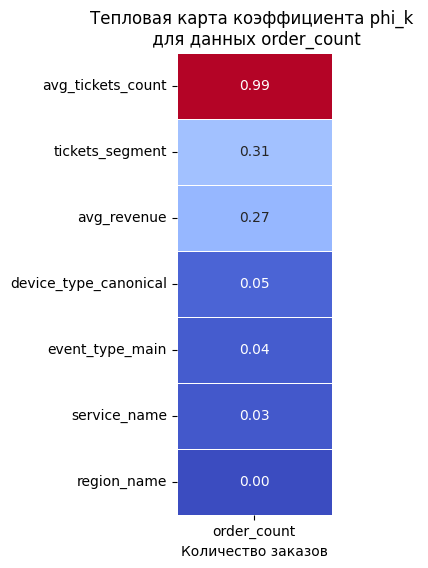

In [68]:
plt.figure(figsize=(2, 6))

data_heatmap = correlation_matrix[correlation_matrix.index != 'order_count'][['order_count']].sort_values(by='order_count', ascending=False)

sns.heatmap(
    data=data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phi_k \n для данных order_count')
plt.xlabel('Количество заказов')

plt.show()

Наиболее связанные признаки с количеством заказов: `avg_tickets_count`, `tickets_segment`, `avg_revenue`.

---

## 5. Общий вывод и рекомендации.

В ходе исследования были проанализированы данные билетного сервиса. Данные включали информацию о пользователях и их заказах. Был составлен профиль для более чем 21 тыс. пользователей, который в последствии анализировался. Акцент исследования был на том, чтобы найти взаимосвязь между оставшимися (совершившими более 1 заказа) пользователями и их признаками. 

### Шаги предобработки данных для исследовательского анализа

- предобработка выбросов - фильтрация данных
- приведения всех данных о выручке к единой валюте - рублям
- исследование пропусков и оптимизация типов данных

### Основные результаты анализа

- В выборке участвовало 20 тыс. пользователей. Около 60% пользователей совершили 2 и более заказов, около 25% пользователей - 5 и более заказов. Средняя выручка с одного заказа - 545.7 рублей.
- Более 60% пользователей, совершивших первый заказ в регионах `Шанырский регион`, `Светополянский округ`, `Широковская область` продолжают совешать заказы в сервисе. Тип мероприятия может влиять, на возврат пользователя, но требуются дополнительные исследования в этом направлении.
- Пользователи, который совершили от 2 до 4-х покупок обычно составляют меньшую среднюю выручку за заказ, чем пользователи, совершившие 5 и более покупок. Пользователи, которые покупают от 2 до 3 билетов с вероятностью более 70% продолжат использовать сервис. Однако, те, кто покупают от 5 и более билетов с вероятностью более 80% не совершат повторной покупки.
- День недели не влияет на удержание пользователя. Однако, те пользователи, которые покупают от 2 до 4 билетов возвращаются в сервис сразу или в течении ближайших дней (от 0 до 5). Люди, покупающие 5 и более билетов, возвращаются в течение 5-20 дней.
- Согласно корреляционному анализу следующие характеристики могут быть связаны с числом покупок: `avg_tickets_count` - среднее количество билетов в заказе, `tickets_segment` - сегмент по количеству билетов в заказе, `avg_revenue` - средняя выручка сервиса с заказа.

### Рекомендации

В сегмент пользователей, покупающие 5 и более билетов в заказе, скорее всего входят определенные группы: например, школьные группы или группы детских летних лагерей. Этот сегмент требует удержания, потому что с 80% вероятностью не совершит повторную покупку. Можно рассмотреть меры по удержанию: например, скидку от покупки 4-х и более билетов или скидку на каждый третий билет. 

Пользователи, совершивших 2 или 4 заказа, с наибольшей вероятностью возвращаются в ближайшие дни. Однако, с меньшей вероятностью вернуться через бОльший промежуток времени. Стоит рассмотреть меры удержания клиентов, например, разработку системы лояльности.

Следует провести дополнительные исследования в направлении влияния типа мероприятия на возврат пользователя. Возможно, некоторые из пользователей более вероятно продолжат использовать сервис в зависимости от их интересов. Тогда стоит сконцентрироваться на привлечении этик пользователей.

Можно рассмотреть инструменты привлечения клиентов в определенные дни недели, которые ассоциируются с наименьшей пользовательской активностью. Скидка в определенный день недели может послужить как фактором удержания пользователя, так и фактором привлечения новых.